# 과제 2 · 시각화 실습 — 그림으로 보고, 검정으로 확인한다 (6주차 · 2026. 10. 19.)

기초지질데이터과학 · **제출: 오늘 23:59, LMS 과제 2 — 이 노트북(.ipynb) 파일 하나** · 배점 5 (코드 작동 2 · 해석 2 · 기록지 1)

**이름:**　김태연　　　　　**학번:**   202001192

- 쓰는 파일: `rayleigh_nitrogen.csv`, `sandstone_two_units.csv` — 왼쪽 📁 파일 창에 끌어다 놓으세요.
- `rayleigh_nitrogen.csv`는 **실제 측정 자료**입니다 — 레일리 경(Lord Rayleigh)이 1893–94년에 잰 질소 질량 15회, 강의 27쪽의 표. `sandstone_two_units.csv`는 **교육용 합성 자료**입니다.
- AI는 자유롭게 씁니다. 쓴 것은 맨 아래 **기록지**에 적습니다. 검증 없는 제출은 해석 0점입니다.
- 오늘의 순서: **그림으로 보고 → 검정으로 확인하고 → 다시 그림을 본다.** 그림의 인상과 검정 결과가 다르면, 어느 쪽이 무엇 때문에 틀렸는지 찾습니다.

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
# 패키지의 한글 글꼴을 직접 등록해 distutils 의존성을 피합니다.
from importlib.metadata import distribution, PackageNotFoundError
from matplotlib import font_manager

try:
    font_package = distribution("koreanize-matplotlib")
except PackageNotFoundError:
    %pip -q install koreanize-matplotlib
    font_package = distribution("koreanize-matplotlib")

font_path = font_package.locate_file("koreanize_matplotlib/fonts/NanumGothic.ttf")
font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams["axes.unicode_minus"] = False

def summary(x, name):
    # 한 집단 요약: 개수 · 평균 · 표준편차(SD) · 표준오차(SE = SD/√n) · 평균의 95% 신뢰구간(t 분포, 강의 156쪽)
    x = pd.Series(x, dtype=float).dropna().to_numpy()
    n, m, s = len(x), x.mean(), x.std(ddof=1)
    se = s / np.sqrt(n)
    h = stats.t.ppf(0.975, n - 1) * se
    print(f"{name:<14} n={n:2d} | 평균 {m:.5f} | SD {s:.5f} | SE {se:.5f} | 95% CI [{m-h:.5f}, {m+h:.5f}]")

def welch(x, y, name):
    # 두 표본 Welch t-검정 — 두 집단의 분산이 같다고 가정하지 않는다(강의 179쪽). 차이 = x 평균 − y 평균
    x = pd.Series(x, dtype=float).dropna().to_numpy()
    y = pd.Series(y, dtype=float).dropna().to_numpy()
    vx, vy = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    t = (x.mean() - y.mean()) / np.sqrt(vx + vy)
    df = (vx + vy) ** 2 / (vx ** 2 / (len(x) - 1) + vy ** 2 / (len(y) - 1))
    p = 2 * stats.t.sf(abs(t), df)
    tc = stats.t.ppf(0.975, df)
    ptxt = f"= {p:.4f}" if p >= 1e-4 else "< 0.0001"
    print(f"{name:<14} 차이 {x.mean()-y.mean():+.5f} | t = {t:6.2f} | df = {df:4.1f} | 임계 t(α=0.05) = {tc:.2f} | p {ptxt}")

## Part A · 레일리의 질소 — 막대가 가린 차이 (약 20분)

1893–94년 겨울, 레일리 경은 질소를 표준 유리구에 채워 질량을 쟀습니다(강의 26–32쪽). **공기**에서 산소를 걷어 내 얻은 질소와 **화학 반응**(NO · N₂O · NH₄NO₂의 분해)으로 얻은 질소를 비교했고, 이 차이가 이듬해 **아르곤 발견**으로 이어졌습니다. 26쪽의 질문 — *"그는 어떻게 동료들을 설득했을까?"*

열: `측정일` · `원료` · `정제제`(산소를 걷어 낸 방법) · `질량_g`

In [45]:
ra = pd.read_csv("rayleigh_nitrogen.csv")
ra["출처"] = np.where(ra["원료"] == "공기", "공기", "화학 반응")
ra

,측정일,원료,정제제,질량_g,출처
0,1893-11-29,NO,뜨거운 철,2.30143,화학 반응
1,1893-12-05,NO,뜨거운 철,2.29816,화학 반응
2,1893-12-06,NO,뜨거운 철,2.30182,화학 반응
3,1893-12-08,NO,뜨거운 철,2.29890,화학 반응
4,1893-12-12,공기,뜨거운 철,2.31017,공기
5,1893-12-14,공기,뜨거운 철,2.30986,공기
6,1893-12-19,공기,뜨거운 철,2.31010,공기
7,1893-12-22,공기,뜨거운 철,2.31001,공기
8,1893-12-26,N2O,뜨거운 철,2.29889,화학 반응
9,1893-12-28,N2O,뜨거운 철,2.29940,화학 반응


**A-1. AI 그림.** AI에게 아래처럼 요청하고, 받은 코드를 다음 칸에 붙여 넣어 **고치지 말고** 실행하세요.

> pandas 데이터프레임 `ra`에서 `출처`(공기 · 화학 반응)별 `질량_g`를 비교하는 그림을 matplotlib으로 그려 줘.

**그림만 보고 내린 판단 (한 줄):** 출처별로 질량 분포가 다른 것이 확인되나 개별적인 점의 크기가 커서 점들의 위치가 너무 뭉쳐져 있어 보인다

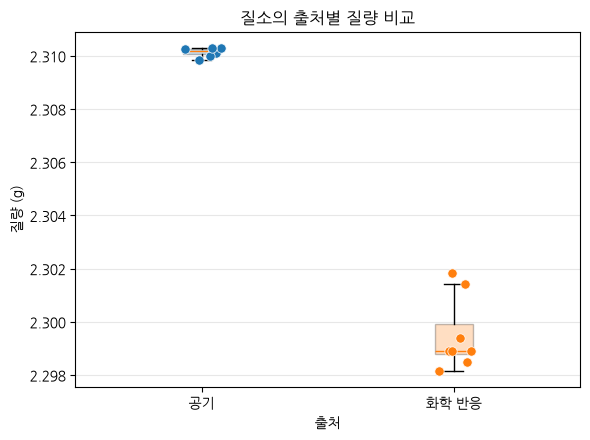

In [46]:
# A-1: AI가 준 코드
sources = ["공기", "화학 반응"]
groups = [ra.loc[ra["출처"] == source, "질량_g"].dropna() for source in sources]
colors = ["tab:blue", "tab:orange"]

fig, ax = plt.subplots(figsize=(6, 4.5))
boxes = ax.boxplot(groups, tick_labels=sources, patch_artist=True, showfliers=False)
for box, color in zip(boxes["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.25)

rng = np.random.default_rng(42)
for position, values, color in zip([1, 2], groups, colors):
    jitter = rng.uniform(-0.08, 0.08, size=len(values))
    ax.scatter(position + jitter, values, color=color, edgecolors="white",
               linewidths=0.5, s=45, zorder=3)

ax.set_xlabel("출처")
ax.set_ylabel("질량 (g)")
ax.set_title("질소의 출처별 질량 비교")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


**A-2. 내 그림.** 원자료 점과 상자그림을 함께 그리세요. 세로축 범위는 자료가 있는 곳으로(31쪽), 축 이름에는 단위를 적습니다. AI에게 시켜도 되지만, 무엇을 바꿨는지는 기록지에 남기세요.

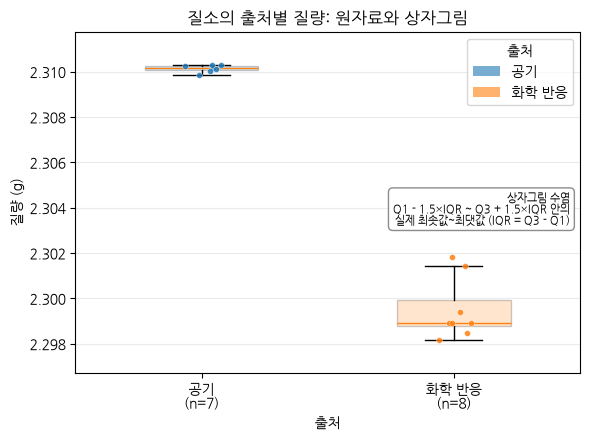

In [55]:
# A-2: 내 그림 (원자료 점 + 상자그림)
from matplotlib.patches import Patch
sources = ["공기", "화학 반응"]
groups = [ra.loc[ra["출처"] == source, "질량_g"].dropna() for source in sources]
colors = ["tab:blue", "tab:orange"]

fig, ax = plt.subplots(figsize=(6, 4.5))
boxes = ax.boxplot(groups, tick_labels=sources, patch_artist=True,
                   showfliers=False, whis=1.5, widths=0.45)
for box, color in zip(boxes["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.2)

# 작은 점과 좌우 흩뿌리기로 겹침을 줄입니다.
rng = np.random.default_rng(42)
for position, values, color in zip([1, 2], groups, colors):
    jitter = rng.uniform(-0.08, 0.08, size=len(values))
    ax.scatter(position + jitter, values, s=18, color=color,
               alpha=0.85, edgecolors="white", linewidths=0.3, zorder=3)

# 자료 범위에 맞게 세로축을 설정합니다.
values = np.concatenate([group.to_numpy() for group in groups])
padding = max(float(np.ptp(values)) * 0.12, 0.0001)
ax.set_ylim(values.min() - padding, values.max() + padding)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
# 출처와 결측값을 제외한 실제 시료 수를 함께 표시합니다.
ax.set_xticks([1, 2],
              [f"{source}\n(n={len(group)})" for source, group in zip(sources, groups)])
ax.set_xlabel("출처")
ax.set_ylabel("질량 (g)")
ax.set_title("질소의 출처별 질량: 원자료와 상자그림")
ax.legend(handles=[Patch(facecolor=color, alpha=0.6, label=source)
                   for source, color in zip(sources, colors)],
          title="출처", loc="upper right")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
# 두 질량 집단 사이의 빈 공간에 공통 설명을 배치합니다.
ax.text(0.98, 0.48,
        "상자그림 수염\nQ1 - 1.5×IQR ~ Q3 + 1.5×IQR 안의\n실제 최솟값~최댓값 (IQR = Q3 - Q1)",
        transform=ax.transAxes, ha="right", va="center", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                  edgecolor="gray", alpha=0.9))
fig.tight_layout()
plt.show()


**A-3. 검정.** 아래 칸을 실행하세요. 두 출처의 차이는 질량의 몇 %인가요? 계산한 t는 임계 t의 몇 배인가요?

**답:** 공기에서 얻은 질소의 평균 질량은 **2.31014 g**, 화학 반응에서 얻은 질소는 **2.29950 g**이며, 평균 차이(공기 − 화학 반응)는 **0.01064 g**이다. 화학 반응 시료의 평균 질량을 기준으로 계산하면 `100 × (2.31013714 − 2.29949750) / 2.29949750 ≈ 0.463%`로, 공기 시료가 약 **0.46% 더 무겁다**.

Welch t검정의 **t ≈ 21.88**, 자유도는 약 **7.22**이며, 유의수준 5% 양측검정의 **임계 t ≈ 2.35**이다. 따라서 계산한 t는 임계 t의 **약 9.31배**(`21.8806 / 2.3502`)로, 임계값을 크게 넘는다.


In [48]:
air = ra.loc[ra["출처"] == "공기", "질량_g"]
chem = ra.loc[ra["출처"] == "화학 반응", "질량_g"]
summary(air, "공기")
summary(chem, "화학 반응")
welch(air, chem, "공기 − 화학")

공기             n= 7 | 평균 2.31014 | SD 0.00016 | SE 0.00006 | 95% CI [2.30999, 2.31028]
화학 반응          n= 8 | 평균 2.29950 | SD 0.00136 | SE 0.00048 | 95% CI [2.29836, 2.30064]
공기 − 화학        차이 +0.01064 | t =  21.88 | df =  7.2 | 임계 t(α=0.05) = 2.35 | p < 0.0001


**A-4. 해석 (각각 한두 문장).**

1. A-1의 그림(또는 30쪽의 막대그래프)은 왜 이 차이를 보여 주지 못했나요? A-2의 그림은 무엇을 바꿔서 보여 주나요? (A-1 그림이 이미 차이를 잘 보여 줬다면, 그 그림이 막대그래프와 무엇이 다른지 쓰세요.)
2. 차이가 **원료**가 아니라 **정제제** 때문일 수는 없나요? 정제제가 같은 시료끼리만 비교해 보고 답하세요. (화학 반응 질소는 모두 '뜨거운 철'로 정제했습니다.)

**1:** 막대그래프와 다르게 질량의 분포가 출처별로 다름을 명확히 보여주며, 또 그 안에서도 점들의 분포를 통해서 분산에 대해 힌트를 얻을 수 있다.

**2:** 정제제가 같은 시료에서도 이미 확인한 바와 같은 차이가 나타남을 확인할 수 있어 정제제는 배제할 수 있다.

정제제: 뜨거운 철
공기 (뜨거운 철)     n= 4 | 평균 2.31004 | SD 0.00013 | SE 0.00007 | 95% CI [2.30982, 2.31025]
화학 (뜨거운 철)     n= 8 | 평균 2.29950 | SD 0.00136 | SE 0.00048 | 95% CI [2.29836, 2.30064]
공기 − 화학        차이 +0.01054 | t =  21.63 | df =  7.3 | 임계 t(α=0.05) = 2.35 | p < 0.0001
평균 차이: 0.01054 g (화학 반응 시료 평균 대비 0.458%)


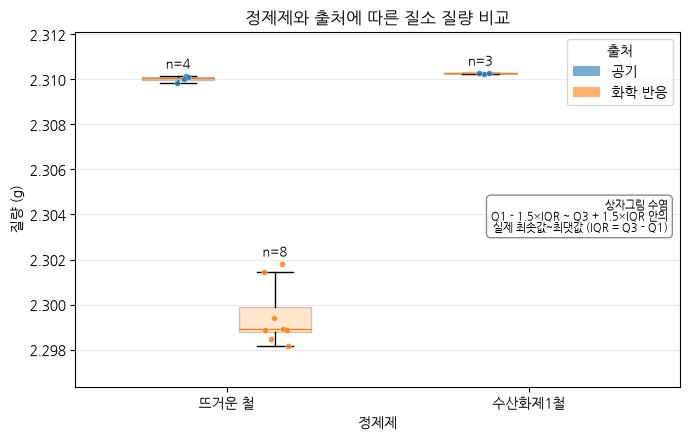

In [49]:
# A-4 ②: 정제제가 같은 시료끼리 비교
# 화학 반응 시료와 정제 조건을 맞추어 '뜨거운 철' 시료만 선택합니다.
ra_iron = ra.loc[ra["정제제"] == "뜨거운 철"].copy()
air_iron = ra_iron.loc[ra_iron["출처"] == "공기", "질량_g"].dropna()
chem_iron = ra_iron.loc[ra_iron["출처"] == "화학 반응", "질량_g"].dropna()

print("정제제: 뜨거운 철")
summary(air_iron, "공기 (뜨거운 철)")
summary(chem_iron, "화학 (뜨거운 철)")
welch(air_iron, chem_iron, "공기 − 화학")

mean_difference = air_iron.mean() - chem_iron.mean()
print(f"평균 차이: {mean_difference:.5f} g "
      f"(화학 반응 시료 평균 대비 {100 * mean_difference / chem_iron.mean():.3f}%)")

# 정제제별 질량 분포를 출처별로 나누어 비교합니다.
from matplotlib.patches import Patch

purifiers = ra["정제제"].dropna().unique().tolist()
source_colors = {"공기": "tab:blue", "화학 반응": "tab:orange"}
source_offsets = {"공기": -0.16, "화학 반응": 0.16}
fig, ax = plt.subplots(figsize=(7, 4.5))
rng = np.random.default_rng(42)

for position, purifier in enumerate(purifiers, start=1):
    for source, color in source_colors.items():
        mass = ra.loc[(ra["정제제"] == purifier) & (ra["출처"] == source),
                      "질량_g"].dropna()
        if mass.empty:
            continue  # 측정되지 않은 조합은 그리지 않습니다.
        center = position + source_offsets[source]
        boxes = ax.boxplot([mass], positions=[center], widths=0.24,
                           patch_artist=True, whis=1.5, showfliers=False,
                           manage_ticks=False)
        boxes["boxes"][0].set_facecolor(color)
        boxes["boxes"][0].set_alpha(0.2)
        jitter = rng.uniform(-0.045, 0.045, size=len(mass))
        ax.scatter(center + jitter, mass, s=18, color=color, alpha=0.85,
                   edgecolors="white", linewidths=0.3, zorder=3)
        ax.text(center, mass.max() + 0.00035, f"n={len(mass)}",
                ha="center", fontsize=9)

mass_all = ra["질량_g"].dropna()
padding = max(float(np.ptp(mass_all.to_numpy())) * 0.15, 0.001)
ax.set_ylim(mass_all.min() - padding, mass_all.max() + padding)
ax.set_xticks(range(1, len(purifiers) + 1), purifiers)
ax.set_xlim(0.5, len(purifiers) + 0.5)
ax.set_xlabel("정제제")
ax.set_ylabel("질량 (g)")
ax.set_title("정제제와 출처에 따른 질소 질량 비교")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.legend(handles=[Patch(facecolor=color, label=source, alpha=0.6)
                   for source, color in source_colors.items()], title="출처")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
# 두 질량 집단 사이의 빈 공간에 공통 설명을 배치합니다.
ax.text(0.98, 0.48,
        "상자그림 수염\nQ1 - 1.5×IQR ~ Q3 + 1.5×IQR 안의\n실제 최솟값~최댓값 (IQR = Q3 - Q1)",
        transform=ax.transAxes, ha="right", va="center", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                  edgecolor="gray", alpha=0.9))
fig.tight_layout()
plt.show()


## Part B · 두 사암층의 밀도 — 그림의 인상과 검정 (약 35분)

**질문:** 한 지역의 하부 **A층**과 상부 **B층** 사암에서 시료를 채취해 겉보기 밀도(g/cm³)를 쟀습니다. **두 층의 밀도는 다른가?** 이 값은 층별 밀도로 이 지역 중력 이상 해석(지하 구조 모델)에 그대로 들어갑니다.

열: `시료번호` · `층` · `채취일` · `밀도`(g/cm³) · `비고`(현장 관찰). 사암 겉보기 밀도는 대략 2.0–2.6 g/cm³이고, 석영 2.65 · 방해석 2.71보다 클 수 없습니다.

In [50]:
ss = pd.read_csv("sandstone_two_units.csv")
print(ss.groupby("층")["밀도"].describe().round(3))
ss

        count   mean    std   min   25%    50%    75%   max
층                                                          
A층(하부)   12.0  2.299  0.031  2.25  2.28  2.295  2.310  2.36
B층(상부)   11.0  2.327  0.074  2.12  2.32  2.350  2.365  2.40


,시료번호,층,채취일,밀도,비고
0,A-01,A층(하부),2025-10-15,2.28,NaN
1,A-02,A층(하부),2025-10-15,2.31,NaN
2,A-03,A층(하부),2025-10-15,2.31,NaN
3,A-04,A층(하부),2025-10-15,2.35,엽리 약함
4,A-05,A층(하부),2025-10-15,2.27,NaN
5,A-06,A층(하부),2025-10-15,2.25,NaN
6,A-07,A층(하부),2025-10-15,2.29,NaN
7,A-08,A층(하부),2025-10-15,2.30,NaN
8,A-09,A층(하부),2025-10-15,2.30,탄질물 포함
9,A-10,A층(하부),2025-10-15,2.29,NaN


**B-1. AI가 흔히 그려 주는 그림.** 아래 코드는 AI에게 "두 층의 밀도를 비교하는 그림을 그려 줘"라고 했을 때 흔히 받는 형태를 그대로 옮긴 것입니다. **고치지 말고** 실행하세요. 그림의 인상을 한 줄로 적고, 1교시 **점검표 다섯 항목**으로 문제를 찾아 적으세요.

**그림의 인상 (한 줄):** 검은 줄이 기둥과 어떤 연관인지 알기 어렵다.

**점검표로 찾은 문제:** 원자료가 없고 0에서 시작하지 않으며 오차 막대가 무엇인지 알 수 없고, 세로축에는 단위가 없다. 또한 제목의 내용인 무게 차이를 밀도 비교 그래프가 담고 있다고 보기 힘들다.

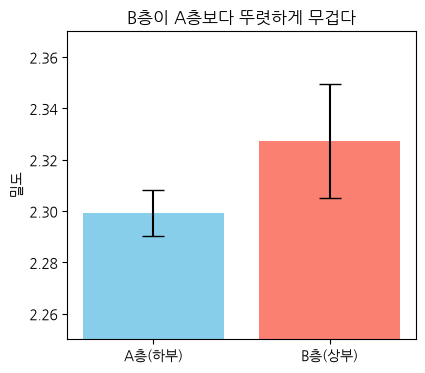

In [51]:
# B-1: AI가 흔히 내놓는 그림 — 고치지 말고 실행
g = ss.groupby("층")["밀도"]
means, sems = g.mean(), g.sem()
plt.figure(figsize=(4.5, 4))
plt.bar(means.index, means.values, yerr=sems.values, capsize=8, color=["skyblue", "salmon"])
plt.ylim(2.25, 2.37)
plt.ylabel("밀도")
plt.title("B층이 A층보다 뚜렷하게 무겁다")
plt.show()

**B-2. 내 그림.** 층마다 **원자료 점 + 상자그림 + 평균의 95% 신뢰구간**을 함께 그리세요(1교시의 '세 겹'). 축 이름과 단위, 오차막대가 무엇인지를 그림 안(범례·제목)에 적습니다. **비고가 있는 시료**가 그림에서 어디에 있는지 확인하세요.

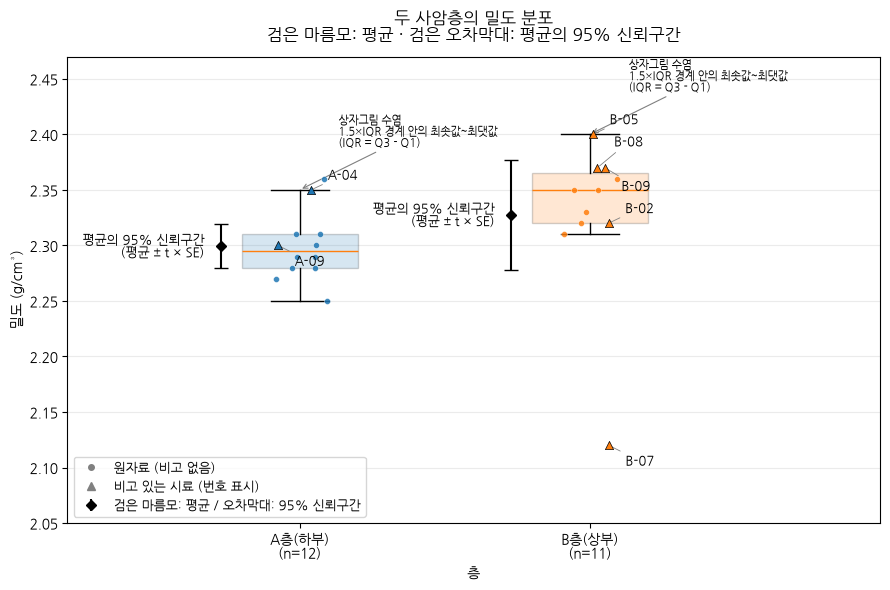

비고가 있는 시료 (삼각형):
시료번호      층   밀도                    비고
A-04 A층(하부) 2.35                 엽리 약함
A-09 A층(하부) 2.30                탄질물 포함
B-02 B층(상부) 2.32                   사층리
B-05 B층(상부) 2.40        방해석 교결, 매우 단단함
B-07 B층(상부) 2.12 노두 표면, 풍화 심함, 손으로 부서짐
B-08 B층(상부) 2.37                방해석 교결
B-09 B층(상부) 2.37                방해석 교결


In [52]:
# B-2: 내 그림 (원자료 점 + 상자그림 + 평균의 95% 신뢰구간)
from matplotlib.lines import Line2D

layers = ["A층(하부)", "B층(상부)"]
colors = ["tab:blue", "tab:orange"]
fig, ax = plt.subplots(figsize=(9, 6))
rng = np.random.default_rng(42)

for position, layer, color in zip([1, 2], layers, colors):
    data = ss.loc[ss["층"] == layer].dropna(subset=["밀도"]).copy()
    density = data["밀도"].to_numpy()

    # 1. 상자그림: 중앙값과 사분위 범위. 모든 원자료는 아래 점으로 표시합니다.
    boxes = ax.boxplot([density], positions=[position], widths=0.4,
                       patch_artist=True, whis=1.5, showfliers=False, manage_ticks=False)
    boxes["boxes"][0].set_facecolor(color)
    boxes["boxes"][0].set_alpha(0.18)
    # 상자그림 수염의 위쪽 끝을 가리켜 95% 신뢰구간과 구분합니다.
    upper_whisker = boxes["caps"][1].get_ydata()[0]
    ax.annotate("상자그림 수염\n1.5×IQR 경계 안의 최솟값~최댓값\n(IQR = Q3 - Q1)",
                xy=(position, upper_whisker), xytext=(28, 30),
                textcoords="offset points", ha="left", va="bottom", fontsize=8,
                arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))


    # 2. 원자료 점: 비고가 있는 시료는 삼각형과 시료번호로 구분합니다.
    x = position + rng.uniform(-0.10, 0.10, size=len(data))
    has_note = data["비고"].fillna("").str.strip().ne("").to_numpy()
    ax.scatter(x[~has_note], density[~has_note], s=18, color=color,
               edgecolors="white", linewidths=0.3, alpha=0.85, zorder=3)
    ax.scatter(x[has_note], density[has_note], s=35, marker="^", color=color,
               edgecolors="black", linewidths=0.5, zorder=4)
    for index in np.flatnonzero(has_note):
        row = data.iloc[index]
        # 번호에 따라 주석을 조금씩 이동해 가까운 점의 글자 겹침을 줄입니다.
        offset_y = {"A-04": 8, "A-09": -14,
                    "B-05": 8, "B-07": -14,
                    "B-08": 16, "B-09": -16}.get(row["시료번호"], 8)
        ax.annotate(row["시료번호"], (x[index], density[index]),
                    xytext=(12, offset_y), textcoords="offset points", fontsize=9,
                    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6))

    # 3. 평균과 t분포로 계산한 평균의 95% 신뢰구간을 표시합니다.
    mean = density.mean()
    se = density.std(ddof=1) / np.sqrt(len(density))
    half_width = stats.t.ppf(0.975, len(density) - 1) * se
    ax.errorbar(position - 0.27, mean, yerr=half_width, fmt="D",
                color="black", capsize=5, markersize=5, elinewidth=1.5, zorder=5)
    # 설명을 오차막대 왼쪽에 상자 없이 직접 표시합니다.
    ax.annotate("평균의 95% 신뢰구간\n(평균 ± t × SE)",
                xy=(position - 0.27, mean), xytext=(-12, 0),
                textcoords="offset points", ha="right", va="center", fontsize=9)


ax.set_xticks([1, 2],
              [f"{layer}\n(n={ss.loc[ss['층'] == layer, '밀도'].count()})"
               for layer in layers])
ax.set_xlim(0.2, 3.0)
all_density = ss["밀도"].dropna()
padding = max(float(np.ptp(all_density.to_numpy())) * 0.25, 0.01)
ax.set_ylim(all_density.min() - padding, all_density.max() + padding)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.set_xlabel("층")
ax.set_ylabel("밀도 (g/cm³)")
ax.set_title("두 사암층의 밀도 분포\n검은 마름모: 평균 · 검은 오차막대: 평균의 95% 신뢰구간", pad=12)
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", color="gray", markersize=4,
           label="원자료 (비고 없음)"),
    Line2D([], [], marker="^", linestyle="none", color="gray", markersize=6,
           label="비고 있는 시료 (번호 표시)"),
    ax.errorbar([], [], yerr=[], fmt="D", color="black", capsize=5,
                markersize=5, label="검은 마름모: 평균 / 오차막대: 95% 신뢰구간")
], loc="lower left", fontsize=9)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

# 그림의 시료번호와 현장 비고를 대조합니다.
note_mask = ss["비고"].fillna("").str.strip().ne("")
print("비고가 있는 시료 (삼각형):")
print(ss.loc[note_mask, ["시료번호", "층", "밀도", "비고"]].to_string(index=False))


**B-3. 검정과 결정.** 먼저 자료 전체로 검정합니다. 그다음 B-2 그림과 비고를 보고, **질문에 비추어** 다르게 다룰 시료가 있는지 정하세요(뺌 · 남김 · 다른 방법). 그 결정대로 다시 검정합니다. 근거는 자료 **밖**에서 옵니다 — 비고, 암석의 물리, 그리고 질문(층의 밀도를 무엇에 쓰나).

| 시료번호 | 값 | 결정 | 근거 (AI 밖의 기준) |
|---|---|---|---|
| b-07 | 2.12 | 뺌 | 상부층의 범위를 과도하게 벗어난 이상치로 판단하였음 |


In [53]:
# B-3: 전체 자료와 결정표 반영 후 자료의 Welch t검정
A = ss.loc[ss["층"] == "A층(하부)", "밀도"].dropna()
B = ss.loc[ss["층"] == "B층(상부)", "밀도"].dropna()

print("[전체 자료]")
summary(A, "A층")
summary(B, "B층 전체")
welch(B, A, "B − A 전체")

# 결정표의 b-07은 CSV의 B-07에 해당합니다. 해당 시료번호만 제외합니다.
excluded_ids = ["B-07"]
exclude_mask = ss["시료번호"].astype(str).str.strip().str.upper().isin(excluded_ids)
print("\n[결정표에 따라 제외하는 시료]")
print(ss.loc[exclude_mask, ["시료번호", "층", "밀도", "비고"]].to_string(index=False))
B_my = ss.loc[(ss["층"] == "B층(상부)") & ~exclude_mask, "밀도"].dropna()

print("\n[B-07 제외 후]")
summary(A, "A층")
summary(B_my, "B층 결정 후")
welch(B_my, A, "B − A 결정 후")


[전체 자료]
A층             n=12 | 평균 2.29917 | SD 0.03118 | SE 0.00900 | 95% CI [2.27936, 2.31898]
B층 전체          n=11 | 평균 2.32727 | SD 0.07377 | SE 0.02224 | 95% CI [2.27771, 2.37683]
B − A 전체       차이 +0.02811 | t =   1.17 | df = 13.2 | 임계 t(α=0.05) = 2.16 | p = 0.2621

[결정표에 따라 제외하는 시료]
시료번호      층   밀도                    비고
B-07 B층(상부) 2.12 노두 표면, 풍화 심함, 손으로 부서짐

[B-07 제외 후]
A층             n=12 | 평균 2.29917 | SD 0.03118 | SE 0.00900 | 95% CI [2.27936, 2.31898]
B층 결정 후        n=10 | 평균 2.34800 | SD 0.02821 | SE 0.00892 | 95% CI [2.32782, 2.36818]
B − A 결정 후     차이 +0.04883 | t =   3.85 | df = 19.8 | 임계 t(α=0.05) = 2.09 | p = 0.0010


**B-4. 결론.** 보조 ②의 틀로 쓰세요.

> 〔어느 자료〕에서 〔무엇을〕 보니 〔수치와 방향 — 차이, p 또는 신뢰구간〕이었다. 이는 〔지질학적 해석〕으로 설명할 수 있다. 다만 〔한계〕 때문에 〔여기까지〕만 말할 수 있다.

**결론:** 두 사암층의 밀도 자료에서 풍화가 심한 B-07을 제외하고 비교한 결과, B층의 평균 밀도는 A층보다 약 0.04883 g/cm³ 높았으며, Welch t검정에서 통계적으로 유의했다(p≈0.0010). 이는 B층 일부 시료의 방해석 교결과 관련될 가능성이 있다. 다만 표본 수가 적은 자료이며, 풍화 시료를 제외한 결과이므로 두 층 전체의 밀도 차이나 그 원인을 확정할 수는 없다.

**B-1 그림의 인상은 검정 결과와 맞았나요? 맞지 않았다면 그림의 어떤 선택 때문인가요? (한두 문장):** 전체 자료의 검정 결과는 p≈0.2621로, B-1 제목의 “뚜렷하게 무겁다”는 주장과 맞지 않았다. 막대그래프의 세로축을 잘라 차이를 과장하고, 원자료를 생략해 풍화 시료 B-07과 B층의 큰 산포를 드러내지 못했기 때문이다.

**B-5. 질문이 바뀌면? (두세 줄)** 질문을 "**풍화가 이 사암의 밀도를 얼마나 낮추나?**"로 바꾸면, 오늘 내린 결정과 그림·검정에서 무엇이 달라지나요? 한 가지 이상.

**답:** 질문이 풍화에 따른 밀도 감소라면, 풍화가 심한 B-07은 제외할 이상치가 아니라 핵심 분석 대상이므로 남겨야 한다. 그림과 검정도 층별 비교에서 같은 층의 풍화 시료와 신선한 시료의 비교로 바꾼다. 

## 짝 상호평가 (약 10분) — 참여 ②

짝과 화면을 바꿔 **짝의 B-2 그림**을 아래 점검표로 평가하고, 평가는 **내 노트북**의 이 표에 적습니다. 그다음 짝에게 받은 지적으로 **내 그림을 고쳐** B-2 아래에 새 칸으로 붙입니다(수정본).

**평가한 짝 (이름):**

| # | 점검 항목 | ○ / △ / ✕ | 한 줄 이유 |
|---|---|---|---|
| ① | 원자료(점)가 보이는가 | | |
| ② | 축 범위가 차이를 숨기거나 키우지 않는가 | | |
| ③ | 오차막대가 무엇인지(SD · SE · 95% CI) 적혀 있는가 | | |
| ④ | 축 이름 · 단위 · 범례가 있는가 | | |
| ⑤ | 그림의 인상이 검정 결과와 맞는가 | | |

**짝에게 받은 지적과 고친 점 (한두 줄):**

## AI 활용 기록지 (5칸) — 최소 2건 (A-1 포함)

| # | ① 도구·모델 | ② 프롬프트 원문 | ③ AI 산출물 (셀 번호·요약) | ④ 검증 — 무엇을 보고 확인했나 | ⑤ 수정 — 무엇을 왜 바꿨나 |
|---|---|---|---|---|---|
| 1 | chatgpt | 원자료 점과 박스와 수염 그래프를 그려주세요. | a-2 | 그래프를 직접 보고 ai 가 레이블과 수염에 대해 그래프에 기재하지 않았음을 확인했다. | 수염 범위와 n 에 값과 점 색의 레이블을 추가했다. |
| 2 | chatgpt | 원자료 점과 박스와 수염 그리고 오차범위 95% 를 나타내는 그래프를 그려주세요. | b-2 | 그래프를 직접 보고 이번에도 ai 가 오차범위와 수염이 무엇을 보여주는지 명시하지 않았음을 확인하고 표에서 비고가 있는 값들을 직접 그래프와 대조하여 확인했다. | 오차범위와 수염에 대해 기술하지 않아 이에 대해 알 수 없으므로 이들에 대해 레이블을 추가했고 비고란이 있는 점들을 대조하며 b07 샘플을 이상치로 보아 제거하기로 하였다. |

**④칸 예시.** "막대그래프의 세로축이 0에서 시작하는지 확인했다" · "오차막대가 무엇인지 코드에서 확인했다 — `sem()`은 표준오차" · "summary()의 평균을 값 몇 개로 손계산해 대조했다" · "그림에서 튀는 점이 표의 어느 시료인지 확인했다". **"AI에게 다시 물어봤다"는 검증이 아닙니다.**